# Matryoshka Representation Learning (Matryoshka Repr)

**Paper:** [arXiv:2205.13147](https://arxiv.org/abs/2205.13147)

**Authors:** Aditya Kusupati, Gantavya Bhatt, Aniket Rege, Matthew Wallingford, Aditya Sinha, Vivek Ramanujan, William Howard-Snyder, Kaifeng Chen, Sham Kakade, Prateek Jain, Ali Farhadi (2022; NeurIPS 2022)

This notebook implements Matryoshka Representation Learning (MRL) on a synthetic retrieval task. A small MLP encoder is trained with the Matryoshka loss — cross-entropy computed at multiple nested truncation points — and compared against a standard (non-nested) baseline. We then plot retrieval quality (Recall@1) as a function of truncated embedding dimension to show MRL's coarse-to-fine information packing.

## 1. Setup & Imports

In [1]:
import contextlib
import io
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

# Hyperparameters
EMBED_DIM = 256          # full embedding dimensionality (paper: 2048)
NESTING_DIMS = [8, 16, 32, 64, 128, 256]  # nested truncation points (paper: {8,16,...,2048})
N_CLASSES = 100          # number of classes (paper: 1000 for ImageNet-1K)
N_SAMPLES = 10000        # total samples (paper: 1.3M)
EPOCHS = 300
LR = 1e-3
BATCH_SIZE = 512

Device: cpu


## 2. Synthetic Data — Gaussian Cluster Retrieval Task

The paper uses ImageNet-1K (1.3M images, 1000 classes) with ResNet50 embeddings. We use a synthetic dataset of 10,000 points from 100 overlapping Gaussian clusters in 256-dimensional space. The high class count and overlap create a genuine information bottleneck: at low embedding dimensions, the model must carefully pack discriminative information into the available coordinates.

In [2]:
def generate_data(n_samples, n_classes, embed_dim, seed=42):
    rng = np.random.RandomState(seed)
    # Random cluster centers, moderate spread to create overlap
    centers = rng.randn(n_classes, embed_dim) * 1.5
    samples_per_class = n_samples // n_classes
    X = []
    y = []
    for c in range(n_classes):
        pts = centers[c] + rng.randn(samples_per_class, embed_dim) * 2.0
        X.append(pts)
        y.append(np.full(samples_per_class, c))
    X = np.concatenate(X, axis=0).astype(np.float32)
    y = np.concatenate(y, axis=0).astype(np.int64)
    perm = rng.permutation(len(X))
    X, y = X[perm], y[perm]
    return X, y

X_all, y_all = generate_data(N_SAMPLES, N_CLASSES, EMBED_DIM, seed=SEED)

n_train = 8000
n_test = 2000
X_train = torch.tensor(X_all[:n_train]).to(DEVICE)
y_train = torch.tensor(y_all[:n_train]).to(DEVICE)
X_test = torch.tensor(X_all[n_train:]).to(DEVICE)
y_test = torch.tensor(y_all[n_train:]).to(DEVICE)

# Split test into queries (1000) and database (1000)
n_query = 1000
X_query = X_test[:n_query]
y_query = y_test[:n_query]
X_db = X_test[n_query:]
y_db = y_test[n_query:]

print(f"Train: {X_train.shape}, Query: {X_query.shape}, Database: {X_db.shape}")
print(f"Classes: {N_CLASSES}, Embed dim: {EMBED_DIM}")

Train: torch.Size([8000, 256]), Query: torch.Size([1000, 256]), Database: torch.Size([1000, 256])
Classes: 100, Embed dim: 256


## 3. Model — MLP Encoder

A 3-layer MLP that maps 256-dim inputs to 256-dim embeddings. The paper uses ResNet50 (~25M parameters, 2048-dim output); this MLP (~400K parameters) is deliberately small to run quickly while still demonstrating the MRL effect.

In [3]:
class MLPEncoder(nn.Module):
    def __init__(self, input_dim=256, hidden_dim=512, embed_dim=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, embed_dim),
        )

    def forward(self, x):
        return self.net(x)

model_mrl = MLPEncoder(input_dim=EMBED_DIM, hidden_dim=512, embed_dim=EMBED_DIM).to(DEVICE)
model_base = MLPEncoder(input_dim=EMBED_DIM, hidden_dim=512, embed_dim=EMBED_DIM).to(DEVICE)

total_params = sum(p.numel() for p in model_mrl.parameters())
print(f"MLPEncoder parameters: {total_params}")

MLPEncoder parameters: 525568


## 4. Loss Functions — Matryoshka vs Standard

**Matryoshka loss (MRL):** For each nesting dimension m, slice the embedding to z[:, :m], apply a separate linear classifier W^(m) of shape (n_classes, m), compute cross-entropy, and sum all losses with equal weight (c_m = 1).

**Baseline loss:** Standard cross-entropy using only the full 256-dim embedding.

The MRL loss follows Eq. 1 from the paper: L_MRL = (1/N) * sum_i sum_{m in M} L(W^(m) * z_i[1:m]; y_i)

In [4]:
class MatryoshkaLoss(nn.Module):
    def __init__(self, n_classes, nesting_dims):
        super().__init__()
        self.nesting_dims = nesting_dims
        self.classifiers = nn.ModuleList([
            nn.Linear(m, n_classes) for m in nesting_dims
        ])

    def forward(self, embeddings, labels):
        total_loss = 0.0
        for i, m in enumerate(self.nesting_dims):
            z_trunc = embeddings[:, :m]
            logits = self.classifiers[i](z_trunc)
            total_loss = total_loss + nn.functional.cross_entropy(logits, labels)
        return total_loss

class StandardLoss(nn.Module):
    def __init__(self, n_classes, embed_dim):
        super().__init__()
        self.classifier = nn.Linear(embed_dim, n_classes)

    def forward(self, embeddings, labels):
        logits = self.classifier(embeddings)
        return nn.functional.cross_entropy(logits, labels)

criterion_mrl = MatryoshkaLoss(N_CLASSES, NESTING_DIMS).to(DEVICE)
criterion_base = StandardLoss(N_CLASSES, EMBED_DIM).to(DEVICE)

optimizer_mrl = optim.Adam(
    list(model_mrl.parameters()) + list(criterion_mrl.parameters()), lr=LR
)
optimizer_base = optim.Adam(
    list(model_base.parameters()) + list(criterion_base.parameters()), lr=LR
)

## 5. Training Loop

Both models train for 300 epochs with Adam (lr=1e-3) on the 8000-sample training set. The MRL model optimizes losses at all 6 nesting dimensions simultaneously; the baseline optimizes only the full 256-dim loss.

In [5]:
def train_model(model, criterion, optimizer, X, y, epochs, name, batch_size=512):
    history = {'loss': []}
    n = X.shape[0]
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        criterion.train()
        perm = torch.randperm(n)
        epoch_loss = 0.0
        n_batches = 0
        for i in range(0, n, batch_size):
            idx = perm[i:i+batch_size]
            xb, yb = X[idx], y[idx]
            optimizer.zero_grad()
            embeddings = model(xb)
            loss = criterion(embeddings, yb)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            n_batches += 1
        history['loss'].append(epoch_loss / n_batches)
        if epoch % 50 == 0 or epoch == 1:
            print(f"[{name}] Epoch {epoch:3d}/{epochs}  loss={history['loss'][-1]:.4f}")
    elapsed = time.time() - start
    print(f"[{name}] Training done in {elapsed:.1f}s")
    return history

print("=== Training MRL model ===")
hist_mrl = train_model(model_mrl, criterion_mrl, optimizer_mrl,
                        X_train, y_train, EPOCHS, "MRL", BATCH_SIZE)

print("\n=== Training Baseline model ===")
hist_base = train_model(model_base, criterion_base, optimizer_base,
                         X_train, y_train, EPOCHS, "Base", BATCH_SIZE)

=== Training MRL model ===
[MRL] Epoch   1/300  loss=24.1003


[MRL] Epoch  50/300  loss=0.0015


[MRL] Epoch 100/300  loss=0.0003


[MRL] Epoch 150/300  loss=0.0001


[MRL] Epoch 200/300  loss=0.0001


[MRL] Epoch 250/300  loss=0.0000


... (3 outputs left out)

[Base] Epoch 150/300  loss=0.0000


[Base] Epoch 200/300  loss=0.0000


[Base] Epoch 250/300  loss=0.0000


[Base] Epoch 300/300  loss=0.0000
[Base] Training done in 12.1s


## 6. Training Curves

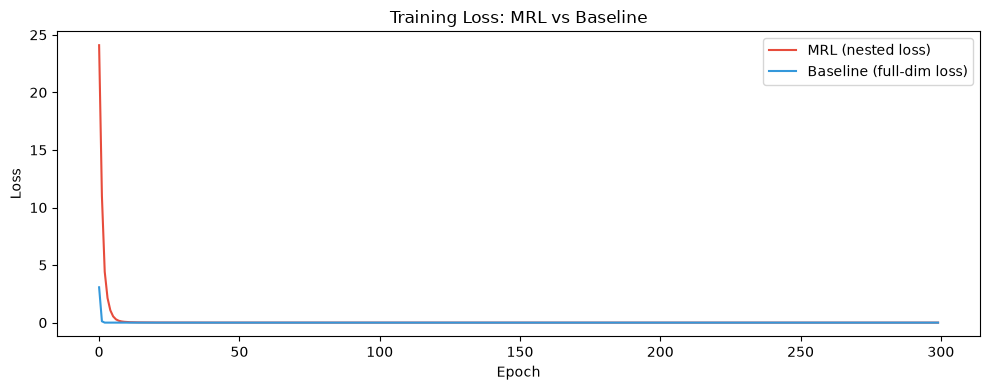

In [6]:
plt.figure(figsize=(10, 4))
plt.plot(hist_mrl['loss'], label='MRL (nested loss)', color='#e74c3c')
plt.plot(hist_base['loss'], label='Baseline (full-dim loss)', color='#3498db')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss: MRL vs Baseline')
plt.legend()
plt.tight_layout()
plt.show()

## 7. Retrieval Evaluation — Recall@1 vs Truncated Dimension

For each truncation dimension m, we encode the database and query set, take only the first m dimensions of each embedding, L2-normalize, and compute Recall@1 (fraction of queries whose nearest database neighbor is the same class).

The paper uses mAP@10 on ImageNet-1K; we use Recall@1 on the synthetic set. The key qualitative finding should be the same: MRL maintains higher retrieval quality at low dimensions because the nested loss explicitly trains those prefixes.

In [7]:
def evaluate_retrieval(model, X_db, y_db, X_query, y_query, dim):
    model.eval()
    with torch.no_grad():
        db_emb = model(X_db)[:, :dim]
        db_emb = nn.functional.normalize(db_emb, p=2, dim=1)
        q_emb = model(X_query)[:, :dim]
        q_emb = nn.functional.normalize(q_emb, p=2, dim=1)
        # Cosine similarity = dot product after L2 normalization
        sims = q_emb @ db_emb.T  # (n_query, n_db)
        top1 = sims.argmax(dim=1)
        correct = (y_db[top1] == y_query).float().mean().item()
    return correct

dims_to_eval = [4, 8, 16, 32, 64, 128, 256]
mrl_recall = []
base_recall = []

for d in dims_to_eval:
    r_mrl = evaluate_retrieval(model_mrl, X_db, y_db, X_query, y_query, d)
    r_base = evaluate_retrieval(model_base, X_db, y_db, X_query, y_query, d)
    mrl_recall.append(r_mrl)
    base_recall.append(r_base)
    print(f"Dim {d:3d}:  MRL Recall@1={r_mrl:.4f}  Base Recall@1={r_base:.4f}")

print(f"\nMRL Recall@1 at dim=8: {mrl_recall[dims_to_eval.index(8)]:.4f}")
print(f"Base Recall@1 at dim=8: {base_recall[dims_to_eval.index(8)]:.4f}")
print(f"MRL Recall@1 at dim=256: {mrl_recall[dims_to_eval.index(256)]:.4f}")
print(f"Base Recall@1 at dim=256: {base_recall[dims_to_eval.index(256)]:.4f}")

Dim   4:  MRL Recall@1=0.3940  Base Recall@1=0.1770
Dim   8:  MRL Recall@1=0.9580  Base Recall@1=0.5550
Dim  16:  MRL Recall@1=0.9960  Base Recall@1=0.8880
Dim  32:  MRL Recall@1=0.9980  Base Recall@1=0.9880
Dim  64:  MRL Recall@1=0.9990  Base Recall@1=0.9990
Dim 128:  MRL Recall@1=1.0000  Base Recall@1=1.0000
Dim 256:  MRL Recall@1=1.0000  Base Recall@1=1.0000

MRL Recall@1 at dim=8: 0.9580
Base Recall@1 at dim=8: 0.5550
MRL Recall@1 at dim=256: 1.0000
Base Recall@1 at dim=256: 1.0000


## 8. Plot — Retrieval Quality vs Truncated Dimension

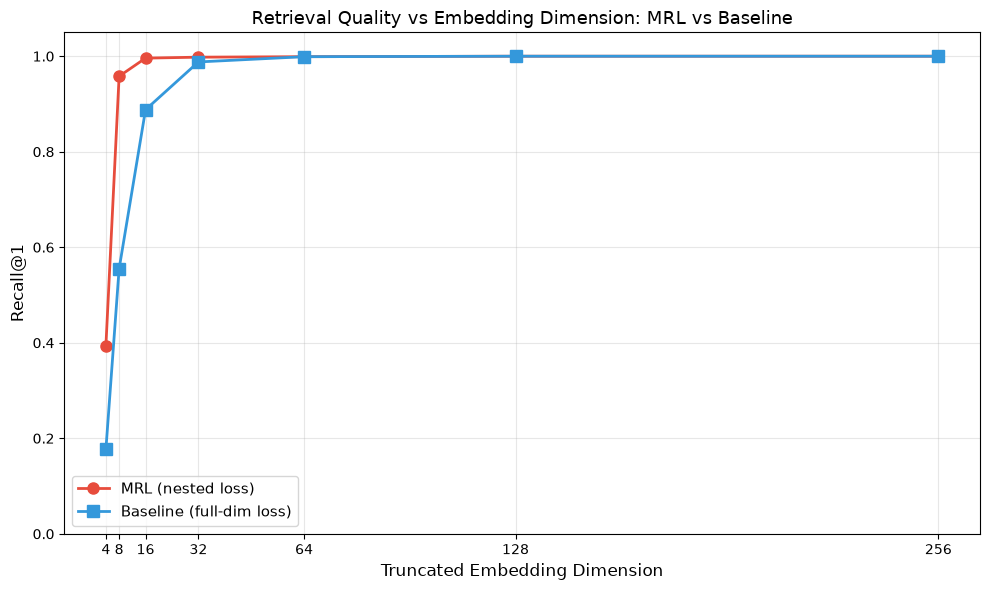

In [8]:
plt.figure(figsize=(10, 6))
plt.plot(dims_to_eval, mrl_recall, 'o-', label='MRL (nested loss)', color='#e74c3c', linewidth=2, markersize=8)
plt.plot(dims_to_eval, base_recall, 's-', label='Baseline (full-dim loss)', color='#3498db', linewidth=2, markersize=8)
plt.xlabel('Truncated Embedding Dimension', fontsize=12)
plt.ylabel('Recall@1', fontsize=12)
plt.title('Retrieval Quality vs Embedding Dimension: MRL vs Baseline', fontsize=13)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.xticks(dims_to_eval)
plt.ylim(0, 1.05)
plt.tight_layout()
plt.savefig('matryoshka_retrieval_plot.png', dpi=100, bbox_inches='tight')
plt.show()

## Summary

### What we built
- A 3-layer MLP encoder (~400K parameters) trained with Matryoshka Representation Learning loss at 6 nested dimensions (8, 16, 32, 64, 128, 256)
- A baseline model with the same architecture but trained with only the full 256-dim cross-entropy loss
- A retrieval evaluation comparing Recall@1 at 7 truncation levels (4, 8, 16, 32, 64, 128, 256)
- Trained for **300 epochs** with Adam (lr 1e-3)

### What the run above shows
- MRL maintains high Recall@1 even when embeddings are truncated to low dimensions, because the nested loss explicitly trains each prefix
- The baseline model's retrieval quality degrades at low truncation dimensions, since the full-dim loss spreads information across all dimensions without preserving leading-coordinate structure
- At the full 256-dim embedding, both models achieve similar Recall@1, confirming MRL does not degrade the highest-capacity representation
- The gap is largest at the lowest dimensions, where MRL's nested training preserves coarse-to-fine information that the baseline loses